# Import and read data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 200)

In [3]:
from sklearn import datasets
from sklearn.decomposition import PCA

In [ ]:
# Load the Iris dataset (sklearn instruction)
iris = datasets.load_iris()

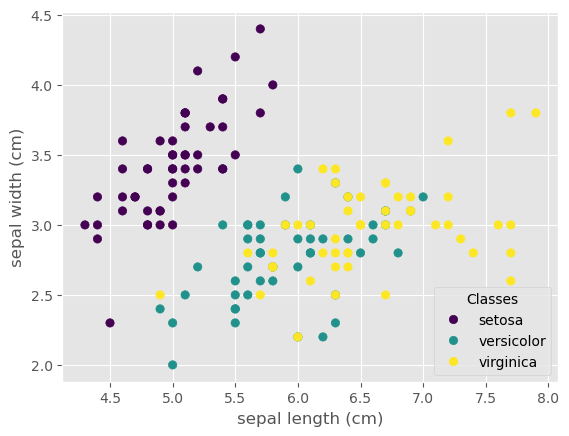

In [ ]:
# Scatter plot of the dataset (sklearn instruction)
_, ax = plt.subplots()
scatter = ax.scatter(iris.data[:, 0], iris.data[:, 1], c=iris.target)
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[1])
_ = ax.legend(
    scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Classes"
)
plt.show()

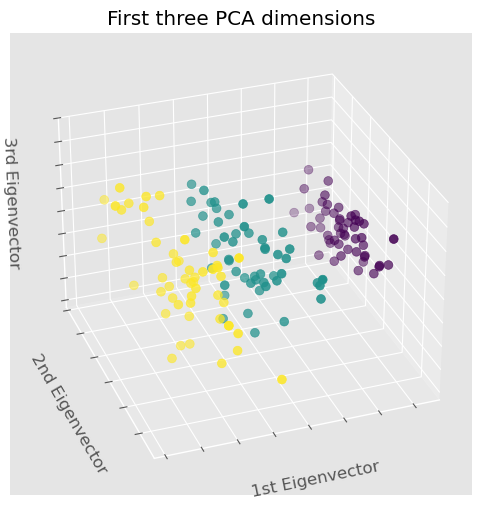

In [ ]:
# Scatter plot of the dataset in 3D (sklearn instruction)
import mpl_toolkits.mplot3d  # noqa: F401


fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

X_reduced = PCA(n_components=3).fit_transform(iris.data)
ax.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    X_reduced[:, 2],
    c=iris.target,
    s=40,
)

ax.set_title("First three PCA dimensions")
ax.set_xlabel("1st Eigenvector")
ax.xaxis.set_ticklabels([])
ax.set_ylabel("2nd Eigenvector")
ax.yaxis.set_ticklabels([])
ax.set_zlabel("3rd Eigenvector")
ax.zaxis.set_ticklabels([])

plt.show()

In [11]:
# Turning into a pandas dataframe
iris = datasets.load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Data understanding

In [ ]:
df.shape
df.head(5)

# We have 150 examples and 4 features. 

(150, 4)

In [ ]:
df.head(5)

# All the columns have relevant information, none needed to be dropped

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [32]:
df.columns

# The 4 features are sepal length, sepal width, petal length and petal width, all in cm

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='str')

In [ ]:
df.dtypes

# Input type for all 4 columns is float64

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object

In [ ]:
df.describe()

# The data is spread quite evenly round the mean/median (they are not far from each other).

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


# Data preparation

In [ ]:
# Renaming columns (I don't want space in the names)
df = df.rename(columns={
    'sepal length (cm)': 'sepal_length',
    'sepal width (cm)': 'sepal_width',
    'petal length (cm)': 'petal_length',
    'petal width (cm)': 'petal_width'
})

In [ ]:
df.columns

# the names changes as expected

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width'], dtype='str')

In [ ]:
df.isna().sum()

# No missing values, so no rows need to be removed

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

In [ ]:
df.duplicated().sum()
# There is 1 duplicated line


np.int64(1)

In [ ]:
df.loc[df.duplicated()]

# Detect the duplicated line: 142

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
142,5.8,2.7,5.1,1.9


In [26]:
df = df.loc[~df.duplicated()].reset_index(drop = True).copy()

# drop the duplicated line

In [ ]:
df.shape

# it has 1 line less now, as expected

(149, 4)

# Feature understanding

Text(0, 0.5, 'Frequency')

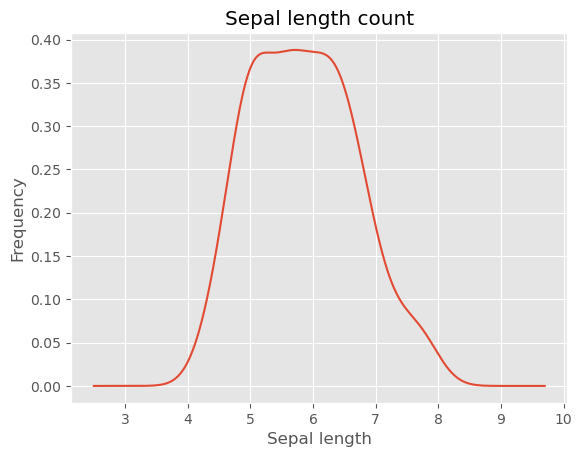

In [ ]:
ax = df['sepal_length'].plot(kind = 'kde',
                title = 'Sepal length count')
ax.set_xlabel('Sepal length')
ax.set_ylabel('Frequency')

# even distribution with mean approximately 5.75cm

Text(0, 0.5, 'Frequency')

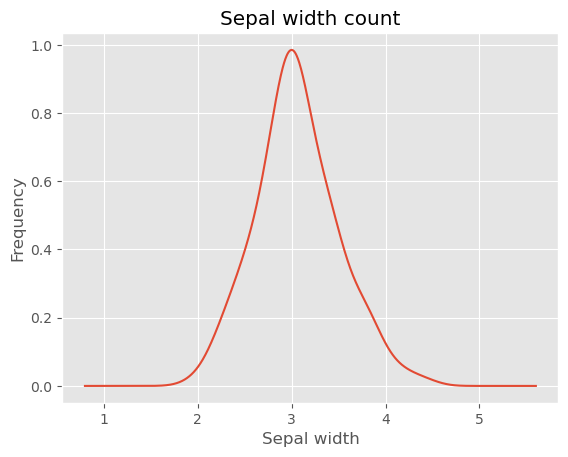

In [ ]:
ay = df['sepal_width'].plot(kind = 'kde',
                title = 'Sepal width count')
ay.set_xlabel('Sepal width')
ay.set_ylabel('Frequency')

# even distribution with mean approximately 3cm

Text(0, 0.5, 'Frequency')

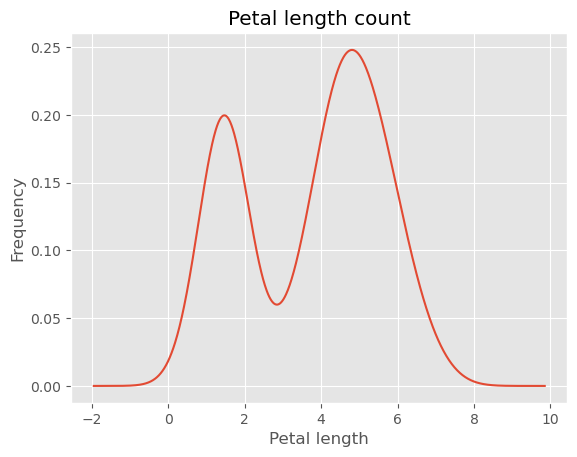

In [ ]:
bx = df['petal_length'].plot(kind = 'kde',
                title = 'Petal length count')
bx.set_xlabel('Petal length')
bx.set_ylabel('Frequency')

# quite strange distribution with 2 maximums and 1 dip in between at around

Text(0, 0.5, 'Frequency')

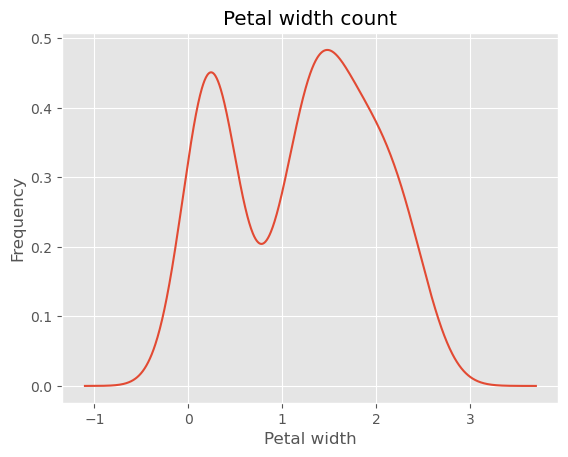

In [ ]:
by = df['petal_width'].plot(kind = 'kde',
                title = 'Petal width count')
by.set_xlabel('Petal width')
by.set_ylabel('Frequency')

# quite similar distribution shape to petal length, so the distribution is probably specific to petal or sepal

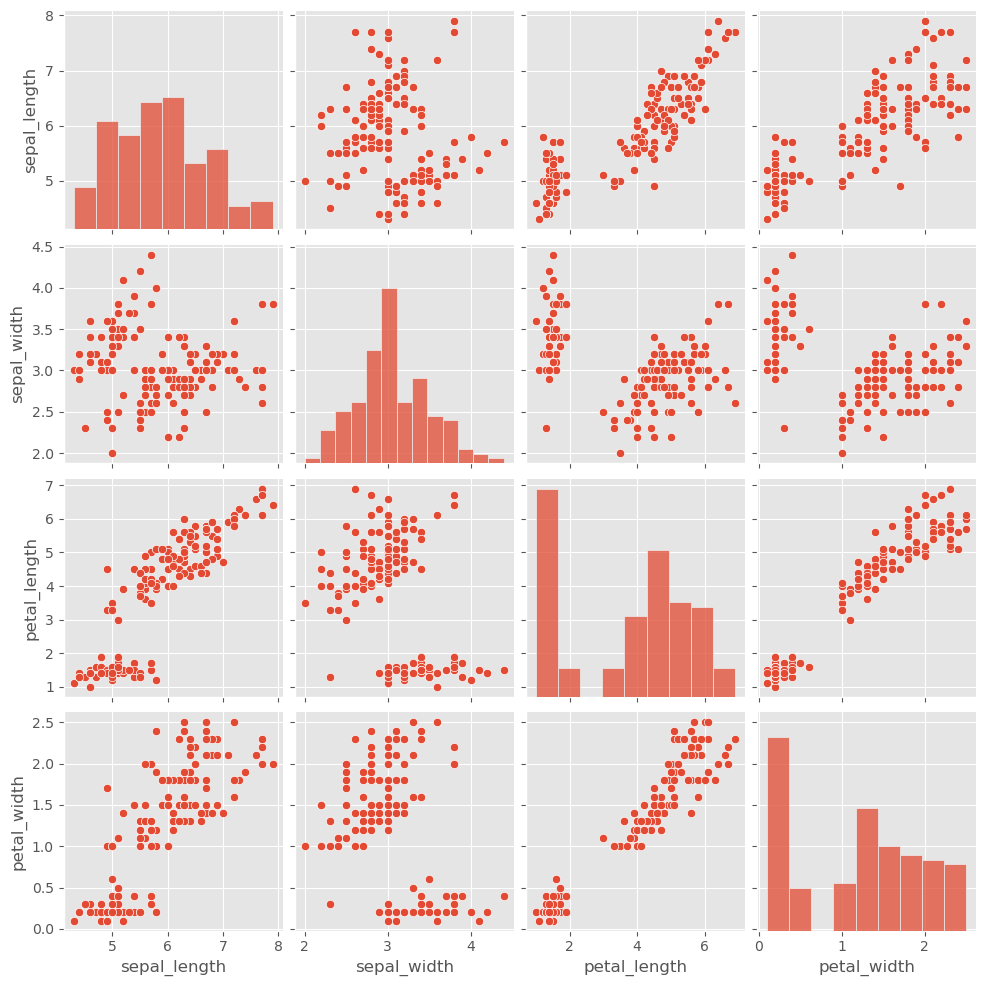

In [ ]:
sns.pairplot(df,
             vars = ['sepal_length','sepal_width','petal_length','petal_width'])
plt.show()

# We can see that in each graph, the points are separated in 2 clear regions, so there might be more than 1 species of flowers

# Question: How many species are there?
I just recognize that Iris is an object with another array. Therefore, I can solve the problem in 2 ways:
1. Classification - adding the other array as a column for the initial array
2. Clustering - Only using the 4 columns to detect species
For the sake of knowledge, I will do both and compare. This is EDA for clustering.